In [ ]:
# NN Images Homework: classify 10 dog breeds (Stanford Dogs dataset)
# Two models compared: (A) a small CNN trained from scratch, (B) transfer learning with MobileNetV2.
# Usage:  python dog_breeds.py  <folder you unzipped the dataset into>  [photo_of_your_dog.jpg]
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# DATA_DIR = "/home/usuario/programacion/ITESO/semestre3/datasets/doggos_test/images/Images/"  # Testing
DATA_DIR = "/home/usuario/programacion/ITESO/semestre3/datasets/doggos/images/Images/"  # Production
MY_DOG = sys.argv[2] if len(sys.argv) > 2 else "/home/usuario/programacion/ITESO/semestre3/datasets/doggos/images/Images/n02107142-Doberman/n02107142_10009.jpg"
#N_BREEDS, IMG, BATCH, SEED = 3, 160, 32, 297974   # 3 breeds used for testing as discussed in class
N_BREEDS, IMG, BATCH, SEED = 10, 160, 32, 297974   # 10 breeds for Production
keras.utils.set_random_seed(SEED)

In [ ]:
# 1) Find the folder that holds one subfolder per breed (e.g. "n02085620-Chihuahua").
#    The Kaggle zip nests it as images/Images/, so we search for it.
def find_breed_root(path):
    for root, dirs, _ in os.walk(path):
        if sum(d.startswith("n0") and "-" in d for d in dirs) >= N_BREEDS:
            return root
    raise FileNotFoundError(f"No breed folders found under {path}")

root = find_breed_root(DATA_DIR)
folders = sorted(d for d in os.listdir(root) if d.startswith("n0"))[:N_BREEDS]   # first 10 breeds
breed_names = [f.split("-", 1)[1].replace("_", " ") for f in folders]           # readable labels
print("Breeds:", breed_names)

Breeds: ['Chihuahua', 'Japanese spaniel', 'Maltese dog', 'Pekinese', 'Shih-Tzu', 'Blenheim spaniel', 'papillon', 'toy terrier', 'Rhodesian ridgeback', 'Afghan hound']


In [ ]:
# 2) Load images: resize every image to 160x160 so they all have the same shape.
#    70% train, 15% validation (to watch overfitting), 15% test (final, untouched score).
train_ds, rest_ds = keras.utils.image_dataset_from_directory(
    root, class_names=folders, label_mode="int", image_size=(IMG, IMG), batch_size=BATCH,
    validation_split=0.30, subset="both", seed=SEED)
# Read the held-out 30% into memory ONCE, so validation and test images can't get reshuffled together
X_rest = np.concatenate([x.numpy() for x, _ in rest_ds])
y_rest = np.concatenate([y.numpy() for _, y in rest_ds])
half = len(y_rest) // 2
X_val, y_val, X_test, y_test = X_rest[:half], y_rest[:half], X_rest[half:], y_rest[half:]
print(f"Train batches: {train_ds.cardinality().numpy()}, validation: {len(y_val)}, test: {len(y_test)} images")

# Data augmentation: random flips/rotations/zooms create "new" training images,
# which fights overfitting when each breed only has ~150-250 photos.
augment = keras.Sequential([layers.RandomFlip("horizontal"),
                            layers.RandomRotation(0.1),
                            layers.RandomZoom(0.1)], name="augmentation")

Found 1919 files belonging to 10 classes.
Using 1344 files for training.
Using 575 files for validation.
Train batches: 42, validation: 287, test: 288 images


In [ ]:
# 3) Model A: small CNN from scratch.
#    Conv2D = learned filters that detect patterns (edges -> textures -> ear/snout shapes);
#    MaxPooling = downsample (keeps the strongest response, tolerates small shifts);
#    softmax output = one probability per breed (they sum to 1).
def build_scratch():
    model = keras.Sequential([
        layers.Input((IMG, IMG, 3)),
        augment,
        layers.Rescaling(1 / 255),                    # pixels 0-255 -> 0-1
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),                          # randomly switch off neurons: less overfitting
        layers.Dense(N_BREEDS, activation="softmax")], name="CNN_from_scratch")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# 4) Model B: transfer learning. MobileNetV2 was already trained on ImageNet (1.2M images),
#    so its filters already "see" fur, ears and faces. We freeze it and only train a new last layer.
def build_transfer():
    weights = None if os.environ.get("NO_PRETRAINED") else "imagenet"
    base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights=weights)
    base.trainable = False                            # frozen: no backpropagation into these layers
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = keras.applications.mobilenet_v2.preprocess_input(x)   # pixels -> [-1, 1], as MobileNetV2 expects
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(N_BREEDS, activation="softmax")(x)
    model = keras.Model(inp, out, name="MobileNetV2_transfer")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

stop_early = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
EPOCHS = {"CNN_from_scratch": 25, "MobileNetV2_transfer": 8}

In [ ]:
# 5) Train both models and evaluate on the untouched test set
results, histories, models = {}, {}, {}
for build in (build_scratch, build_transfer):
    model = build()
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=(X_val, y_val), epochs=EPOCHS[model.name],
                     callbacks=[stop_early], verbose=2)
    seconds = time.time() - t0
    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    report = classification_report(y_test, y_pred, labels=range(N_BREEDS), target_names=breed_names,
                                   output_dict=True, zero_division=0)
    results[model.name] = {"Accuracy": report["accuracy"],
                           "Precision (macro)": report["macro avg"]["precision"],
                           "Recall (macro)": report["macro avg"]["recall"],
                           "F1 (macro)": report["macro avg"]["f1-score"],
                           "Train time (s)": seconds, "Trainable weights": int(
                               sum(np.prod(w.shape) for w in model.trainable_weights))}
    histories[model.name], models[model.name] = hist.history, model
    print(f"\n{model.name}\n", classification_report(y_test, y_pred, labels=range(N_BREEDS),
                                                       target_names=breed_names, zero_division=0))

print("\n=== Test-set comparison ===")
for name, r in results.items():
    print(name, {k: round(v, 3) for k, v in r.items()})

Epoch 1/25


/home/usuario/programacion/ITESO/semestre3/aprendizajemachin/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


42/42 - 7s - 169ms/step - accuracy: 0.1310 - loss: 2.2950 - val_accuracy: 0.1150 - val_loss: 2.2862
Epoch 2/25
42/42 - 6s - 136ms/step - accuracy: 0.1347 - loss: 2.2845 - val_accuracy: 0.1150 - val_loss: 2.2762
Epoch 3/25
42/42 - 6s - 138ms/step - accuracy: 0.1458 - loss: 2.2714 - val_accuracy: 0.1289 - val_loss: 2.2572
Epoch 4/25
42/42 - 6s - 137ms/step - accuracy: 0.1637 - loss: 2.2640 - val_accuracy: 0.1951 - val_loss: 2.2477
Epoch 5/25
42/42 - 6s - 136ms/step - accuracy: 0.1830 - loss: 2.2399 - val_accuracy: 0.1882 - val_loss: 2.2354
Epoch 6/25
42/42 - 6s - 139ms/step - accuracy: 0.1949 - loss: 2.2303 - val_accuracy: 0.2056 - val_loss: 2.2170
Epoch 7/25
42/42 - 6s - 143ms/step - accuracy: 0.1994 - loss: 2.2207 - val_accuracy: 0.2021 - val_loss: 2.2232
Epoch 8/25
42/42 - 6s - 145ms/step - accuracy: 0.2158 - loss: 2.2083 - val_accuracy: 0.2195 - val_loss: 2.2080
Epoch 9/25
42/42 - 6s - 148ms/step - accuracy: 0.1860 - loss: 2.2155 - val_accuracy: 0.2056 - val_loss: 2.2066
Epoch 10/25


/home/usuario/programacion/ITESO/semestre3/aprendizajemachin/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


42/42 - 8s - 199ms/step - accuracy: 0.5632 - loss: 1.3573 - val_accuracy: 0.8711 - val_loss: 0.4867
Epoch 2/8
Epoch 2/8
42/42 - 5s - 110ms/step - accuracy: 0.8534 - loss: 0.5030 - val_accuracy: 0.9233 - val_loss: 0.3059
Epoch 3/8
42/42 - 5s - 114ms/step - accuracy: 0.8765 - loss: 0.3995 - val_accuracy: 0.9094 - val_loss: 0.2901
Epoch 4/8
42/42 - 5s - 112ms/step - accuracy: 0.8921 - loss: 0.3383 - val_accuracy: 0.9129 - val_loss: 0.2622
Epoch 5/8
42/42 - 5s - 125ms/step - accuracy: 0.9115 - loss: 0.2784 - val_accuracy: 0.9199 - val_loss: 0.2356
Epoch 6/8
42/42 - 6s - 139ms/step - accuracy: 0.9085 - loss: 0.2805 - val_accuracy: 0.9233 - val_loss: 0.2187
Epoch 7/8
42/42 - 5s - 121ms/step - accuracy: 0.9152 - loss: 0.2526 - val_accuracy: 0.9303 - val_loss: 0.2224
Epoch 8/8
42/42 - 5s - 124ms/step - accuracy: 0.9189 - loss: 0.2398 - val_accuracy: 0.9268 - val_loss: 0.2178

MobileNetV2_transfer
                      precision    recall  f1-score   support

          Chihuahua       0.90     

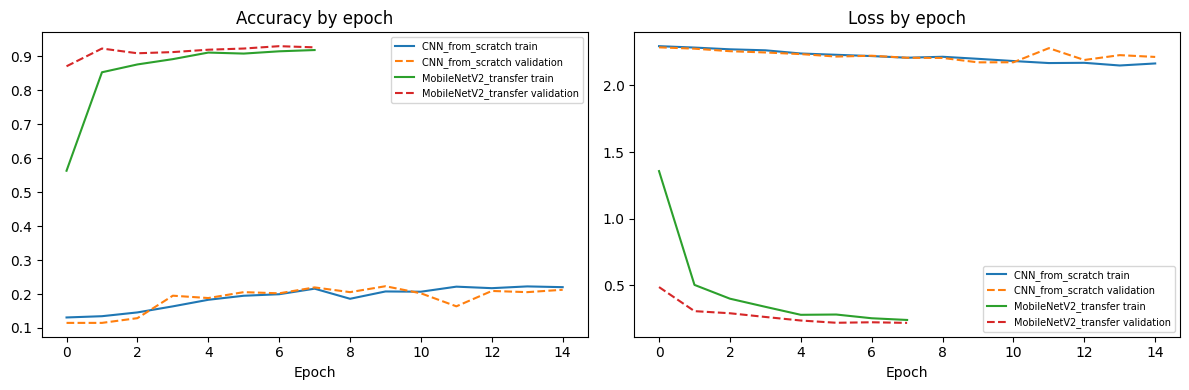

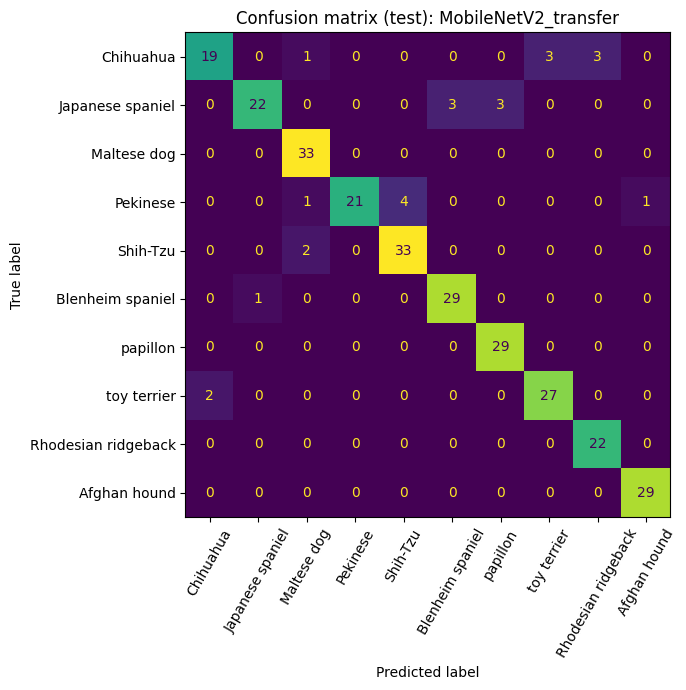

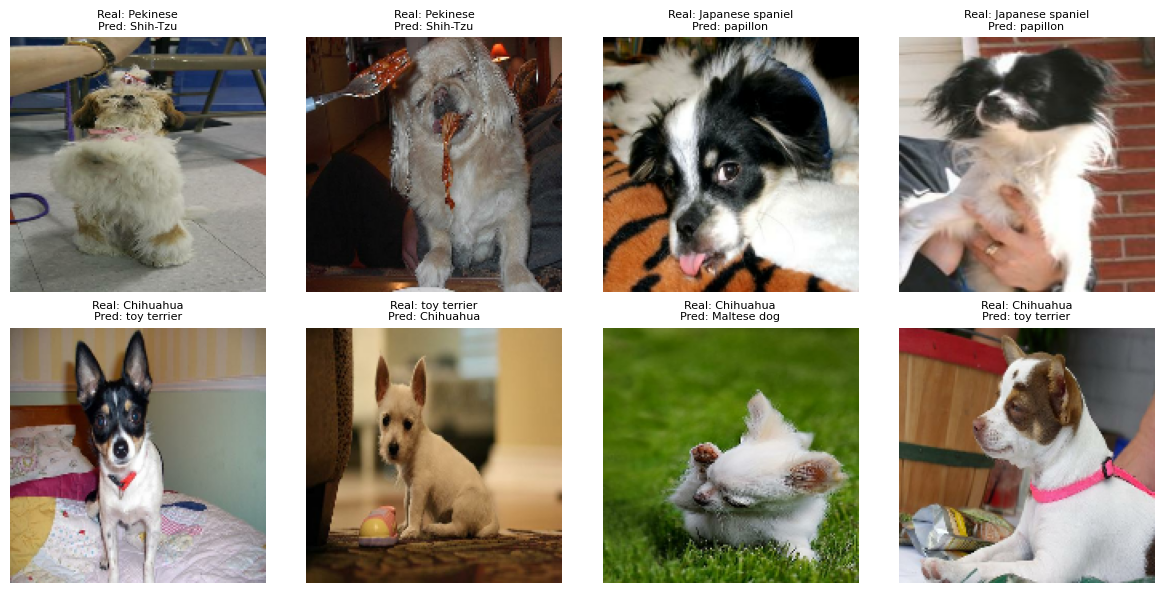

In [ ]:
# 6) Figures for the slides
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h["accuracy"], label=f"{name} train")
    ax[0].plot(h["val_accuracy"], "--", label=f"{name} validation")
    ax[1].plot(h["loss"], label=f"{name} train")
    ax[1].plot(h["val_loss"], "--", label=f"{name} validation")
ax[0].set_title("Accuracy by epoch"); ax[1].set_title("Loss by epoch")
for a in ax: a.set_xlabel("Epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150)

best_name = max(results, key=lambda n: results[n]["Accuracy"])
best = models[best_name]
y_best = best.predict(X_test, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_best, labels=range(N_BREEDS)), display_labels=breed_names).plot(
    ax=ax, xticks_rotation=60, colorbar=False)
ax.set_title(f"Confusion matrix (test): {best_name}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150)

# Misclassified examples (what the network confuses)
wrong = np.where(y_best != y_test)[0][:8]
if len(wrong):
    fig, ax = plt.subplots(2, 4, figsize=(12, 6))
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), wrong):
        a.imshow(X_test[i].astype("uint8"))
        a.set_title(f"Real: {breed_names[y_test[i]]}\nPred: {breed_names[y_best[i]]}", fontsize=8)
    plt.tight_layout(); plt.savefig("misclassified.png", dpi=150)


My dog, top 3: [('Rhodesian ridgeback', 0.72), ('toy terrier', 0.229), ('Chihuahua', 0.027)]
Note: the model only knows these 10 breeds; a mixed or other breed is forced into one of them.


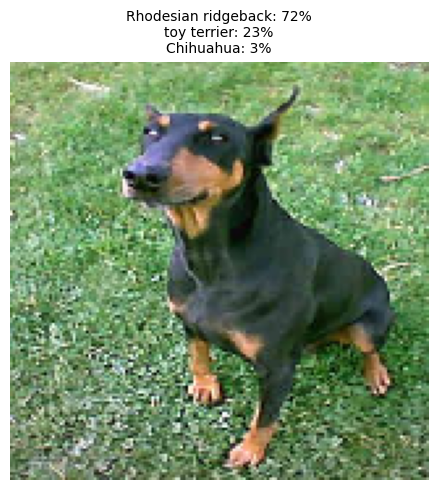

In [ ]:
# 7) Test with your dog: top-3 breeds predicted by the best model
if MY_DOG:
    img = keras.utils.load_img(MY_DOG, target_size=(IMG, IMG))
    probs = best.predict(np.expand_dims(keras.utils.img_to_array(img), 0), verbose=0)[0]
    top3 = probs.argsort()[::-1][:3]
    plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
    plt.title("\n".join(f"{breed_names[i]}: {probs[i]:.0%}" for i in top3), fontsize=10)
    plt.tight_layout(); plt.savefig("my_dog.png", dpi=150)
    print("\nMy dog, top 3:", [(breed_names[i], round(float(probs[i]), 3)) for i in top3])
    print("Note: the model only knows these 10 breeds; a mixed or other breed is forced into one of them.")
plt.show()